# Eksperimen B v3 — Studi generalisasi threshold dan interaksi preprocessing

**Dokumen pendamping wajib:** `README.md`, `PROTOCOL.md` dan `protocol/frozen_v2_params.json`.

**Mode development** mereproduksi penelitian versi 2 dan hasil-hasilnya bersifat **eksploratori** karena 16 sekuens test telah ditinjau.

**Mode confirmatory** memakai enam kategori CDnet2014 yang belum digunakan pada versi 2, membekukan parameter hasil tuning 320 px, menolak sekuens lama, dan tidak melakukan tuning. Mode ini adalah evaluasi *out-of-category/domain-shift*, **bukan** klaim angka leaderboard resmi CDnet 2014. Sumber data CDnet harus disediakan sendiri.

**Syarat interpretasi:** hasil confirmatory hanya berlaku sebagai data independen jika enam kategori tersebut belum pernah dipakai untuk memilih parameter, algoritma, atau hipotesis. Uji statistik menggunakan kategori sebagai unit inferensial. Tidak ada hasil eksperimen baru yang disertakan dalam paket ini.


In [2]:
import os

# Mode penelitian
os.environ["CDNET_MODE"] = "confirmatory"

# Lokasi output
os.environ["CDNET_OUT_DIR"] = "working/results-v3-confirmatory"

# Verifikasi
print("MODE:", os.environ["CDNET_MODE"])
print("OUTPUT:", os.environ["CDNET_OUT_DIR"])

MODE: confirmatory
OUTPUT: working/results-v3-confirmatory


In [3]:
import itertools
import json
import os
import platform
import random
import re
import sys
import time
from pathlib import Path
import hashlib
from paper_protocol import (DEV_CATEGORIES, UNSEEN_CATEGORIES, validate_protocol, score_pixel_counts,
                            category_signflip_p)

import cv2
import matplotlib

if 'ipykernel' not in sys.modules:  # skrip biasa (PyCharm): simpan gambar tanpa membuka jendela
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from tqdm.auto import tqdm

print('OpenCV', cv2.__version__)


OpenCV 5.1.0


C:\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Jalankan dari root folder paket: `python experiment_b_cdnet2014_paper_v3.py`
# Pada confirmatory jangan mengubah threshold setelah memeriksa hasil!
MODE = os.environ.get('CDNET_MODE', 'development').lower()
if MODE not in ('development', 'confirmatory'):
    raise ValueError('CDNET_MODE harus development atau confirmatory')
DEFAULT_DATA = os.environ.get('CDNET_DATA_DIR', 'C:\\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\SkySet')
CFG = {
    'mode': MODE,
    'data_dir': DEFAULT_DATA,
    'categories': list(UNSEEN_CATEGORIES if MODE == 'confirmatory' else DEV_CATEGORIES),
    'max_seqs_per_category': None,
    'max_eval_frames': None,
    'sequences': None,
    'resize_width': 320,  # wajib 320px saat confirmatory agar cocok dengan hyperparameter beku versi 2
    'min_area_ratio': 0.001,
    'gt_close_kernel': 5,
    'iou_thr': 0.5,
    'seed': 42,
    'tune_per_category': 0 if MODE == 'confirmatory' else 2,
    'n_boot': int(os.environ.get('CDNET_BOOTSTRAPS', '5000')),
    'cv_threads': 1,
    'n_jobs': max(1, int(os.environ.get('CDNET_N_JOBS', str(min(4, os.cpu_count() or 1))))),
    'bench_frames': int(os.environ.get('CDNET_BENCH_FRAMES', '300')),
    'bench_repeats': int(os.environ.get('CDNET_BENCH_REPEATS', '5')),
    'out_dir': os.environ.get('CDNET_OUT_DIR', 'working/results-v3-' + MODE),
    'run_tuning': MODE == 'development',
    'tuned_params_file': os.environ.get('CDNET_FROZEN_PARAMS', 'protocol/frozen_v2_params.json') if MODE == 'confirmatory' else None,
    'historical_manifest': os.environ.get('CDNET_SEEN_MANIFEST', 'protocol/seen_v2.json'),
    'run_ablation': True,
    'run_gt_sensitivity': True,
    'qualitative': True,
}

# Parameter default tiap algoritma.
ALGO_PARAMS = {
    'frame_diff': {'fixed_thr': 25, 'otsu_floor': 10},
    'mog2': {'history': 500, 'var_threshold': 16, 'detect_shadows': True},
    'knn': {'history': 500, 'dist2_threshold': 400.0, 'detect_shadows': True},
    'farneback': {
        'pyr_scale': 0.5, 'levels': 3, 'winsize': 15, 'iterations': 3, 'poly_n': 5, 'poly_sigma': 1.2,
        'flow_thr': 1.0,       # piksel/frame (pada resolusi kerja)
        'mag_scale': 32.0,     # skala magnitudo -> 8-bit agar bisa di-Otsu
        'otsu_floor': 10,
    },
}
# Pre/post-processing sama secara konfigurasi; transformasinya tetap spesifik algoritma.
# Jangan menyebut keempat algoritma memiliki response/threshold identik.
STD = {'blur_ksize': 5, 'threshold': 'fixed', 'morph': True}
ALGOS = {'B1': 'frame_diff', 'B2': 'mog2', 'B3': 'knn', 'B4': 'farneback'}
LABELS = {'B1': 'B1 Frame Difference', 'B2': 'B2 MOG2', 'B3': 'B3 KNN', 'B4': 'B4 Farneback'}

# Satu parameter sensitivitas per algoritma; nilai default HARUS ada di grid.
TUNE_GRID = {
    'frame_diff': ('fixed_thr', [2, 3, 4, 5, 6, 8, 10, 15, 20, 25, 30, 40]),   # run 1: optimum di tepi (10) -> grid diperluas
    'mog2': ('var_threshold', [8, 16, 25, 36, 50]),
    'knn': ('dist2_threshold', [200.0, 400.0, 600.0, 900.0, 1400.0]),
    'farneback': ('flow_thr', [0.25, 0.5, 1.0, 1.5, 2.0, 3.0]),
}
ABLATION_ALGOS = ['frame_diff', 'mog2']   # faktorial penuh; Otsu hanya untuk frame_diff/farneback
OTSU_FLOORS = [0, 5, 10, 15, 20]          # sensitivitas lantai Otsu (frame_diff)

# Varian konstruksi box GT dari mask (uji kekokohan). 'primer' dipakai di semua tabel utama.
GT_VARIANTS = {
    'primer': {'close': CFG['gt_close_kernel'], 'min_area_ratio': CFG['min_area_ratio']},
    'tanpa_close': {'close': 0, 'min_area_ratio': CFG['min_area_ratio']},
    'close9': {'close': 9, 'min_area_ratio': CFG['min_area_ratio']},
    'area_kecil': {'close': CFG['gt_close_kernel'], 'min_area_ratio': CFG['min_area_ratio'] / 2},
    'area_besar': {'close': CFG['gt_close_kernel'], 'min_area_ratio': CFG['min_area_ratio'] * 2},
}

OUT = Path(CFG['out_dir'])
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = max(1, int(CFG['n_jobs']))
cv2.setNumThreads(CFG['cv_threads'])
EMPTY = np.zeros((0, 4))
MOTION = 255  # label groundtruth CDnet: 0 static, 50 hard shadow, 85 luar ROI, 170 unknown, 255 motion
SHADOW = 50   # dihitung sebagai background (negatif), seperti praktik umum penggunaan CDnet
SHOW = 'ipykernel' in sys.modules
REPORT = []   # potongan markdown untuk report.md
RNG = np.random.default_rng(CFG['seed'])


<>:6: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
<>:6: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
C:\Users\Administrator\AppData\Local\Temp\ipykernel_5572\595991141.py:6: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
  DEFAULT_DATA = os.environ.get('CDNET_DATA_DIR', 'C:\\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\SkySet')


In [5]:
def mask_to_boxes(mask, min_area):
    """Mask biner -> ndarray (n, 4) [x1, y1, x2, y2]; kontur kecil dibuang."""
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        if cv2.contourArea(c) >= min_area:
            x, y, w, h = cv2.boundingRect(c)
            boxes.append((x, y, x + w, y + h))
    return np.array(boxes, dtype=float).reshape(-1, 4)


def iou_matrix(g, p):
    g, p = g[:, None, :], p[None, :, :]
    iw = np.clip(np.minimum(g[..., 2], p[..., 2]) - np.maximum(g[..., 0], p[..., 0]), 0, None)
    ih = np.clip(np.minimum(g[..., 3], p[..., 3]) - np.maximum(g[..., 1], p[..., 1]), 0, None)
    inter = iw * ih
    ag = (g[..., 2] - g[..., 0]) * (g[..., 3] - g[..., 1])
    ap = (p[..., 2] - p[..., 0]) * (p[..., 3] - p[..., 1])
    return inter / (ag + ap - inter + 1e-9)


def best_iou_per_gt(g, p):
    """IoU terbaik tiap box GT terhadap semua prediksi (0 bila tak ada prediksi)."""
    return np.zeros(len(g)) if len(p) == 0 else iou_matrix(g, p).max(axis=1)


def match_boxes(g, p, thr):
    """Pencocokan satu-ke-satu (greedy menurun menurut IoU), IoU >= thr -> (jumlah TP, jumlah IoU TP)."""
    if len(g) == 0 or len(p) == 0:
        return 0, 0.0
    m = iou_matrix(g, p)
    pairs = sorted(((m[i, j], i, j) for i in range(m.shape[0]) for j in range(m.shape[1])
                    if m[i, j] >= thr), reverse=True)
    used_g, used_p, n, s = set(), set(), 0, 0.0
    for v, i, j in pairs:
        if i in used_g or j in used_p:
            continue
        used_g.add(i)
        used_p.add(j)
        n += 1
        s += v
    return n, s


def gt_boxes_from_labels(g, vcfg, area, cache):
    """Label GT (uint8) -> box gerak. `cache` dipakai bersama antar varian pada frame yang sama."""
    if 'm' not in cache:
        cache['m'] = (g == MOTION).astype(np.uint8) * 255
    m, k = cache['m'], vcfg['close']
    if k:
        if k not in cache:
            cache[k] = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((k, k), np.uint8))
        m = cache[k]
    return mask_to_boxes(m, vcfg['min_area_ratio'] * area)


In [6]:
class MotionDetector:
    """frame BGR -> bounding box gerak (n, 4); mask biner akhir tersedia di `self.mask`.

    Urutan: [GaussianBlur] -> algoritma -> [Otsu] -> mask ROI -> [Morphology open+close] -> kontur -> box.
    `params` menimpa ALGO_PARAMS[algo] (dipakai untuk tuning/ablasi).
    """

    def __init__(self, algo, blur_ksize=0, threshold='fixed', morph=False, params=None, frame_area=1):
        if algo not in ALGO_PARAMS:
            raise ValueError(f'Algoritma tidak dikenal: {algo}')
        self.algo, self.blur_ksize, self.threshold, self.morph = algo, blur_ksize, threshold, morph
        self.p = {**ALGO_PARAMS[algo], **(params or {})}
        self.min_area = CFG['min_area_ratio'] * frame_area
        self.prev, self.bg, self.mask, self.n_calls = None, None, None, 0
        if algo == 'mog2':
            self.bg = cv2.createBackgroundSubtractorMOG2(
                history=self.p['history'], varThreshold=self.p['var_threshold'],
                detectShadows=self.p['detect_shadows'])
        elif algo == 'knn':
            self.bg = cv2.createBackgroundSubtractorKNN(
                history=self.p['history'], dist2Threshold=self.p['dist2_threshold'],
                detectShadows=self.p['detect_shadows'])
        self.k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        self.k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

    def _binarize(self, img8, fixed_thr, otsu_floor):
        if self.threshold == 'otsu':
            otsu, _ = cv2.threshold(img8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            # Lantai wajib: tanpa itu frame statis (hanya noise) tetap di-Otsu menjadi "gerakan".
            thr = max(otsu, otsu_floor)
        else:
            thr = fixed_thr
        return cv2.threshold(img8, thr, 255, cv2.THRESH_BINARY)[1]

    def process(self, frame, roi=None, want_boxes=True):
        img = cv2.GaussianBlur(frame, (self.blur_ksize, self.blur_ksize), 0) if self.blur_ksize else frame
        p = self.p
        if self.bg is not None:                                  # MOG2 / KNN
            # KNN memakai RNG global OpenCV: tanpa menyetel seed per panggilan, hasilnya bergantung pada state
            # proses (urutan eksperimen, serial vs paralel). Seed per frame membuatnya reprodusibel.
            self.n_calls += 1
            cv2.setRNGSeed(CFG['seed'] + self.n_calls)
            fg = self.bg.apply(img)
            mask = np.where(fg == 255, 255, 0).astype(np.uint8)  # 127 = bayangan -> dibuang
        else:                                                    # Frame Difference / Farneback
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            prev, self.prev = self.prev, gray
            if prev is None:
                self.mask = np.zeros(gray.shape, np.uint8)
                return EMPTY
            if self.algo == 'frame_diff':
                mask = self._binarize(cv2.absdiff(gray, prev), p['fixed_thr'], p['otsu_floor'])
            else:
                flow = cv2.calcOpticalFlowFarneback(
                    prev, gray, None, p['pyr_scale'], p['levels'], p['winsize'],
                    p['iterations'], p['poly_n'], p['poly_sigma'], 0)
                mag8 = np.clip(cv2.magnitude(flow[..., 0], flow[..., 1]) * p['mag_scale'], 0, 255).astype(np.uint8)
                mask = self._binarize(mag8, p['flow_thr'] * p['mag_scale'], p['otsu_floor'])
        if roi is not None:                                      # protokol CDnet: hanya ROI yang dinilai
            mask = cv2.bitwise_and(mask, roi)
        if self.morph:
            mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, self.k_open)
            mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, self.k_close)
        self.mask = mask                                         # keluaran piksel (sebelum saringan luas kontur)
        return mask_to_boxes(mask, self.min_area) if want_boxes else EMPTY


In [7]:
def index_frames(folder):
    """{nomor_frame (1-based): path} dari nama file seperti in000001.jpg / gt000001.bmp."""
    out = {}
    for p in folder.iterdir():
        m = re.search(r'(\d+)', p.stem)
        if m and p.suffix.lower() in ('.jpg', '.jpeg', '.png', '.bmp'):
            out[int(m.group(1))] = p
    return dict(sorted(out.items()))


def discover_sequences():
    seqs = []
    for t in sorted(Path(CFG['data_dir']).rglob('temporalROI.txt')):
        d = t.parent
        if not ((d / 'input').is_dir() and (d / 'groundtruth').is_dir()):
            continue
        cat = d.parent.name
        if CFG['categories'] and cat not in CFG['categories']:
            continue
        if CFG['sequences'] and f'{cat}/{d.name}' not in CFG['sequences']:
            continue
        seqs.append({'id': f'{cat}/{d.name}', 'category': cat, 'dir': d})
    if CFG['max_seqs_per_category']:
        kept, count = [], {}
        for s in seqs:
            count[s['category']] = count.get(s['category'], 0) + 1
            if count[s['category']] <= CFG['max_seqs_per_category']:
                kept.append(s)
        seqs = kept
    return seqs


def prepare_sequence(seq):
    """Metadata saja (cepat). Mask GT dibaca per frame saat evaluasi."""
    d = seq['dir']
    roi_start, roi_end = map(int, re.findall(r'\d+', (d / 'temporalROI.txt').read_text())[:2])
    inputs, gts = index_frames(d / 'input'), index_frames(d / 'groundtruth')
    if not inputs or not gts:
        raise ValueError(f'Missing input or groundtruth images in {d}')
    missing_input = sorted(n for n in gts if roi_start <= n <= roi_end and n not in inputs)
    if missing_input:
        raise ValueError(f'GT without matching input in {d}: {missing_input[:8]}')
    first = cv2.imread(str(inputs[min(inputs)]))
    if first is None:
        raise IOError(f'Could not decode first frame of {d}')
    h0, w0 = first.shape[:2]
    scale = CFG['resize_width'] / w0 if CFG['resize_width'] else 1.0
    size = (int(round(w0 * scale)), int(round(h0 * scale)))
    last = roi_end if not CFG['max_eval_frames'] else min(roi_end, roi_start + CFG['max_eval_frames'] - 1)
    roi = None
    roi_img = cv2.imread(str(d / 'ROI.bmp'), cv2.IMREAD_GRAYSCALE)
    if roi_img is not None:
        roi = (cv2.resize(roi_img, size, interpolation=cv2.INTER_NEAREST) > 0).astype(np.uint8) * 255
    seq.update(inputs=inputs, gts=gts, roi_start=roi_start, roi_end=roi_end, last=last, scale=scale,
               size=size, roi=roi, n_scored=sum(1 for n in gts if roi_start <= n <= last))
    return seq


def make_split(seqs):
    """Pembagian tune/test per kategori dengan seed tetap (didokumentasikan di splits.csv)."""
    if CFG['mode'] == 'confirmatory':
        return {s['id']: 'test' for s in seqs}
    rng = random.Random(CFG['seed'])
    split = {}
    for cat in sorted({s['category'] for s in seqs}):
        ids = sorted(s['id'] for s in seqs if s['category'] == cat)
        k = min(CFG['tune_per_category'], max(len(ids) - 1, 0))
        tune = set(rng.sample(ids, k)) if k else set()
        for i in ids:
            split[i] = 'tune' if i in tune else 'test'
    return split


In [8]:
BOX_KEYS = ['tp', 'fp', 'fn', 'tn', 'iou_sum', 'n_gt_boxes', 'n_pred_boxes', 'b_tp', 'b_iou_sum']


def account(c, boxes, g):
    """Akumulasi metrik level frame & box untuk satu varian GT."""
    pred_pos, gt_pos = len(boxes) > 0, len(g) > 0
    c['tp' if gt_pos and pred_pos else 'fp' if pred_pos else 'fn' if gt_pos else 'tn'] += 1
    c['n_pred_boxes'] += len(boxes)
    c['n_gt_boxes'] += len(g)
    if gt_pos and pred_pos:
        c['iou_sum'] += float(best_iou_per_gt(g, boxes).sum())
        n, s = match_boxes(g, boxes, CFG['iou_thr'])
        c['b_tp'] += n
        c['b_iou_sum'] += s


def run_sequence_multi(seq, experiments, limit=None, mode='full', variants=('primer',)):
    """Satu lintasan frame untuk SEMUA eksperimen (detektor terpisah -> hasil identik dengan serial).

    - Frame sebelum temporalROI hanya memanaskan model; hanya frame di [roi_start, last] yang punya
      file GT yang dinilai (frame tanpa GT dilewati, bukan dianggap negatif).
    - Piksel (utama): positif = label 255; negatif = label 0 atau 50 (hard shadow = background); 85/170 diabaikan.
    - mode='pixel': hanya metrik piksel (untuk tuning, lebih cepat). mode='full': + frame & box per varian GT.
    - Waktu = hanya `process()` (blur+algoritma+ROI+morfologi+kontur); baca JPEG/GT tidak dihitung.
    - `limit`: hanya N frame pertama, tanpa GT (untuk benchmark FPS).
    """
    cv2.setNumThreads(CFG['cv_threads'])
    W, H = seq['size']
    area = W * H
    full = mode == 'full'
    dets = {e: MotionDetector(frame_area=area, **cfg) for e, cfg in experiments.items()}
    cs = {e: dict(frames=0, proc_time=0.0, eval_frames=0, px_tp=0, px_fp=0, px_fn=0, px_tn=0,
                  var={v: {k: 0 if k not in ('iou_sum', 'b_iou_sum') else 0.0 for k in BOX_KEYS}
                       for v in variants}) for e in experiments}
    k = 0
    for n, path in seq['inputs'].items():
        if n > seq['last'] or (limit and k >= limit):
            break
        frame = cv2.imread(str(path))
        if frame is None:
            continue
        if seq['scale'] != 1.0:
            frame = cv2.resize(frame, seq['size'], interpolation=cv2.INTER_AREA)
        k += 1
        g = None
        if not limit and n >= seq['roi_start'] and n in seq['gts']:
            g = cv2.imread(str(seq['gts'][n]), cv2.IMREAD_GRAYSCALE)
            if g is None:
                raise IOError(f'Ground truth frame failed to decode: {seq["gts"][n]}')
            if g.shape[::-1] != (W, H):
                g = cv2.resize(g, (W, H), interpolation=cv2.INTER_NEAREST)
        if g is not None:
            # GT box sekunder dan hitungan piksel harus memakai cakupan ROI yang konsisten.
            eligible = (seq['roi'] != 0) if seq['roi'] is not None else np.ones(g.shape, dtype=bool)
            g_eval = g.copy()
            g_eval[~eligible] = 85  # diabaikan untuk metrik & pembentukan GT boxes
            valid_codes = np.isin(g, [0, 50, 85, 170, 255])
            if not valid_codes.all():
                raise ValueError(f'Unknown GT label in {seq["id"]} frame {n}. Use NEAREST GT resizing.')
            pos, neg = g_eval == MOTION, (g_eval == 0) | (g_eval == SHADOW)
            n_pos, n_neg = int(np.count_nonzero(pos)), int(np.count_nonzero(neg))
            if full:
                cache = {}
                gt_b = {v: gt_boxes_from_labels(g_eval, GT_VARIANTS[v], area, cache) for v in variants}
        for e, det in dets.items():
            t0 = time.perf_counter()
            boxes = det.process(frame, seq['roi'], want_boxes=full)
            c = cs[e]
            c['proc_time'] += time.perf_counter() - t0
            c['frames'] += 1
            if g is None:
                continue
            p = det.mask > 0
            # Ground truth masks prevalidated and ROI-clipped once per frame.
            tp = int(np.count_nonzero(p & pos))
            fp = int(np.count_nonzero(p & neg))
            c['eval_frames'] += 1
            c['px_tp'] += tp
            c['px_fp'] += fp
            c['px_fn'] += n_pos - tp
            c['px_tn'] += n_neg - fp
            if full:
                for v in variants:
                    account(c['var'][v], boxes, gt_b[v])
    return cs


def _flatten(c, variants):
    row = {k: c[k] for k in ('frames', 'proc_time', 'eval_frames', 'px_tp', 'px_fp', 'px_fn', 'px_tn')}
    for v in variants:
        pre = '' if v == 'primer' else f'{v}__'
        for key, val in c['var'][v].items():
            row[pre + key] = val
    return row


def _div(a, b):
    return a / b.where(b > 0)


def add_metrics(df):
    """Metrik turunan: frame (accuracy, f1, mcc), box (iou, box_f1, iou_tp), piksel CDnet, fps."""
    for pre in [''] + [c[:-2] for c in df.columns if c.endswith('__tp')]:
        tp, fp, fn, tn = (df[pre + k].astype(float) for k in ('tp', 'fp', 'fn', 'tn'))
        df[pre + 'accuracy'] = _div(tp + tn, tp + fp + fn + tn)
        df[pre + 'f1'] = _div(2 * tp, 2 * tp + fp + fn)
        den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
        df[pre + 'mcc'] = (tp * tn - fp * fn) / den.where(den > 0)
        df[pre + 'iou'] = _div(df[pre + 'iou_sum'], df[pre + 'n_gt_boxes'])
        bt, npred, ngt = (df[pre + k].astype(float) for k in ('b_tp', 'n_pred_boxes', 'n_gt_boxes'))
        df[pre + 'box_precision'] = _div(bt, npred)
        df[pre + 'box_recall'] = _div(bt, ngt)
        df[pre + 'box_f1'] = _div(2 * bt, npred + ngt)
        df[pre + 'iou_tp'] = _div(df[pre + 'b_iou_sum'], bt)
    tp, fp, fn, tn = (df['px_' + k].astype(float) for k in ('tp', 'fp', 'fn', 'tn'))
    df['px_recall'] = _div(tp, tp + fn)
    df['px_spec'] = _div(tn, tn + fp)
    df['px_fpr'] = 1 - df['px_spec']
    df['px_fnr'] = 1 - df['px_recall']
    df['px_precision'] = _div(tp, tp + fp)
    df['px_f'] = _div(2 * tp, 2 * tp + fp + fn)
    df['px_pwc'] = 100 * _div(fp + fn, tp + fp + fn + tn)
    df['fps'] = _div(df['frames'], df['proc_time'])
    return df


def run_suite(experiments, tag, seq_list, mode='full', variants=('primer',), limit=None, n_jobs=1):
    """Menjalankan semua eksperimen pada semua sekuens (paralel antar sekuens bila n_jobs > 1).
    Waktu per-frame TIDAK valid saat paralel (proses berebut CPU) -> proc_time = NaN; FPS dari benchmark serial."""
    variants = list(variants)
    order = sorted(seq_list, key=lambda s: -s['last'])  # terpanjang dulu -> beban merata
    if n_jobs > 1:
        gen = Parallel(n_jobs=n_jobs, return_as='generator')(
            delayed(run_sequence_multi)(s, experiments, limit, mode, variants) for s in order)
    else:
        gen = (run_sequence_multi(s, experiments, limit, mode, variants) for s in order)
    rows = []
    for s, cs in tqdm(zip(order, gen), total=len(order), desc=tag):
        for e, c in cs.items():
            rows.append({'exp': e, 'algo': experiments[e]['algo'], 'seq': s['id'], 'condition': s['category'],
                         'split': s.get('split', ''), **_flatten(c, variants)})
    df = pd.DataFrame(rows)
    if n_jobs > 1:
        df['proc_time'] = np.nan
    return add_metrics(df)


def benchmark_fps(experiments):
    """Measured processing FPS with ONE active detector per timed trial.

    Decode, resize and GT I/O are excluded from processing timer. No multi-model
    contention in the measured loop. Not a full-video real-time throughput claim.
    """
    subset = [next(s for s in sorted(seqs, key=lambda t: t['id']) if s['category'] == cat)
              for cat in sorted({s['category'] for s in seqs})]
    recs = {}
    for exp, cfg in experiments.items():
        observations = []
        for r in range(CFG['bench_repeats'] + 1):
            d = run_suite({exp: cfg}, f'FPS {exp} #{r}', subset, mode='full',
                          limit=CFG['bench_frames'], n_jobs=1)
            if r == 0:  # discard entire first run as warmup
                continue
            frames = float(d.frames.sum())
            proc = float(d.proc_time.sum())
            observations.append(frames / proc if proc > 0 else np.nan)
        recs[exp] = observations
    f = pd.DataFrame(recs)
    out = pd.DataFrame({'fps_median': f.median(), 'fps_min': f.min(), 'fps_max': f.max()})
    out.index.name = 'exp'
    return out


In [9]:
def catmean(d, cols):
    """Konvensi CDnet: rerata metrik per sekuens -> per kategori -> keseluruhan (tiap kategori berbobot sama)."""
    return d.groupby(['exp', 'condition'])[cols].mean().groupby('exp').mean()


def boot_catmean(groups, n_boot):
    groups = [g for g in groups if len(g)]
    return np.mean([g[RNG.integers(0, len(g), (n_boot, len(g)))].mean(axis=1) for g in groups], axis=0)


def cat_ci(d, exp, col):
    """Rerata antar-kategori + CI 95% (bootstrap bertingkat: sekuens diambil ulang di dalam tiap kategori)."""
    sub = d[d.exp == exp]
    groups = [g[col].dropna().values for _, g in sub.groupby('condition') if g[col].notna().any()]
    if not groups:
        return np.nan, np.nan, np.nan
    lo, hi = np.percentile(boot_catmean(groups, CFG['n_boot']), [2.5, 97.5])
    return float(np.mean([g.mean() for g in groups])), float(lo), float(hi)


def holm_adjust(ps):
    ps = np.asarray(ps, float)
    out = np.full(len(ps), np.nan)
    idx = [i for i in np.argsort(ps) if not np.isnan(ps[i])]
    run = 0.0
    for r, i in enumerate(idx):
        run = max(run, min(1.0, (len(idx) - r) * ps[i]))
        out[i] = run
    return out


def contrast_row(x, cat):
    """x: kontras per sekuens (Series berindeks seq). Efek = rerata antar-kategori; p = Wilcoxon per sekuens."""
    x = x.dropna()
    n = len(x)
    row = {'n': n, 'n_categories': 0, 'efek': np.nan, 'ci_lo': np.nan, 'ci_hi': np.nan,
           'median_seq': np.nan, 'menang': 0, 'p': np.nan, 'p_seq_exploratory': np.nan}
    if n == 0:
        return row
    c = cat.loc[x.index]
    groups = [x[c == k].values for k in sorted(c.unique())]
    row['n_categories'] = len(groups)
    row['efek'] = float(np.mean([g.mean() for g in groups]))
    # Category is inferential unit; exact sign-flip on category mean differences.
    row['p'] = category_signflip_p(np.array([g.mean() for g in groups]))
    row['ci_lo'], row['ci_hi'] = np.percentile(boot_catmean(groups, CFG['n_boot']), [2.5, 97.5])
    row['median_seq'], row['menang'] = float(x.median()), int((x > 0).sum())
    if n >= 5 and (x != 0).any():
        try:
            row['p_seq_exploratory'] = float(stats.wilcoxon(x).pvalue)
        except ValueError:
            pass
    return row


def seq_cat(d):
    return d.drop_duplicates('seq').set_index('seq')['condition']


def paired_stats(d, metric, pairs):
    """pairs: [(a, b)] -> efek = b - a. Holm atas semua pasangan dalam daftar ini."""
    wide = d.pivot(index='seq', columns='exp', values=metric)
    cat = seq_cat(d)
    rows = [{'a': a, 'b': b, **contrast_row(wide[b] - wide[a], cat)} for a, b in pairs]
    out = pd.DataFrame(rows)
    out['p_holm'] = holm_adjust(out['p'].values)
    return out


def factorial_effects(d, cells, factors, metric):
    """cells: {exp_id: (level_f1, level_f2, ...)} dengan level 0/1. Efek utama & interaksi per sekuens."""
    wide = d[d.exp.isin(list(cells))].pivot(index='seq', columns='exp', values=metric).dropna()
    cat = seq_cat(d)
    k, rows = len(factors), []
    for r in range(1, k + 1):
        for S in itertools.combinations(range(k), r):
            eff = sum(wide[c] * float(np.prod([2 * cells[c][i] - 1 for i in S])) for c in cells) / 2 ** (k - 1)
            rows.append({'efek_nama': ' x '.join(factors[i] for i in S), **contrast_row(eff, cat)})
    out = pd.DataFrame(rows)
    out['p_holm'] = holm_adjust(out['p'].values)
    return out


def tex_escape(s):
    for a, b in (('\\', ' '), ('&', '\\&'), ('%', '\\%'), ('_', '\\_'), ('#', '\\#')):
        s = s.replace(a, b)
    return s


def save_table(df, name, caption, index=False):
    """Simpan CSV + LaTeX (booktabs) dan tambahkan ke report.md. df berisi string/angka siap tampil."""
    t = df.reset_index() if index else df
    t.to_csv(OUT / f'{name}.csv', index=False)
    cols = [str(c) for c in t.columns]
    lines = ['\\begin{table}[t]', '\\centering', f'\\caption{{{tex_escape(caption)}}}', f'\\label{{tab:{name}}}',
             '\\begin{tabular}{l' + 'c' * (len(cols) - 1) + '}', '\\toprule',
             ' & '.join(tex_escape(c) for c in cols) + ' \\\\', '\\midrule']
    lines += [' & '.join(tex_escape(str(x)) for x in r) + ' \\\\' for r in t.itertuples(index=False)]
    lines += ['\\bottomrule', '\\end{tabular}', '\\end{table}']
    (OUT / f'{name}.tex').write_text('\n'.join(lines) + '\n', encoding='utf-8')
    md = ['| ' + ' | '.join(cols) + ' |', '|' + '---|' * len(cols)]
    md += ['| ' + ' | '.join(str(x) for x in r) + ' |' for r in t.itertuples(index=False)]
    REPORT.append(f'### {caption}\n\n' + '\n'.join(md) + '\n')
    print(f'\n== {caption} ==')
    print(t.to_string(index=False))


def savefig(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    if SHOW:
        plt.show()
    plt.close(fig)


def fmt(m, lo=None, hi=None, d=3):
    if pd.isna(m):
        return '-'
    return f'{m:.{d}f}' if lo is None else f'{m:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]'


def fmt_p(p):
    return '-' if pd.isna(p) else ('<0.001' if p < 0.001 else f'{p:.3f}')


def stats_table(st, name_cols):
    out = pd.DataFrame({**name_cols(st), 'n sekuens': st['n'], 'n kategori': st['n_categories'],
                        'efek [CI95]': [fmt(r.efek, r.ci_lo, r.ci_hi) for r in st.itertuples()],
                        'menang': [f'{r.menang}/{r.n}' for r in st.itertuples()],
                        'p kategori': [fmt_p(p) for p in st['p']],
                        'p Holm': [fmt_p(p) for p in st['p_holm']],
                        'p Wilcoxon seq eksploratori': [fmt_p(p) for p in st['p_seq_exploratory']]})
    return out


In [10]:
seqs = discover_sequences()
if not seqs:
    raise FileNotFoundError(
        f"Tidak ada sekuens CDnet di {CFG['data_dir']} (butuh folder berisi input/, groundtruth/, "
        "temporalROI.txt). Cek path dan filter CFG['categories'].")
seqs = [prepare_sequence(s) for s in tqdm(seqs, desc='metadata')]
no_gt = [s['id'] for s in seqs if s['n_scored'] == 0]
if no_gt:
    print('PERINGATAN: sekuens tanpa GT pada rentang temporalROI dibuang:', no_gt)
seqs = [s for s in seqs if s['n_scored'] > 0]
PROTOCOL_AUDIT = validate_protocol(CFG, seqs, CFG['historical_manifest'])
if CFG['mode'] == 'confirmatory':
    print('CONFIRMATORY: parameter dibekukan; sekuens lama dilarang; enam kategori baru diwajibkan.')
else:
    print('DEVELOPMENT/EXPLORATORY: semua hasil lama sudah pernah dilihat dan bukan validasi baru.')
SPLIT = make_split(seqs)
for s in seqs:
    s['split'] = SPLIT[s['id']]
tune_seqs = [s for s in seqs if s['split'] == 'tune']
test_seqs = [s for s in seqs if s['split'] == 'test']
pd.DataFrame([{'seq': s['id'], 'category': s['category'], 'split': s['split'], 'size': s['size'],
               'roi': f"{s['roi_start']}-{s['roi_end']}", 'frame_dinilai': s['n_scored']} for s in seqs]
             ).to_csv(OUT / 'splits.csv', index=False)
print(f'{len(seqs)} sekuens: {len(tune_seqs)} tune, {len(test_seqs)} test (seed={CFG["seed"]})')
for sp in ('tune', 'test'):
    print(f'  {sp}:', ', '.join(s['id'] for s in seqs if s['split'] == sp))
if CFG['resize_width']:
    print(f"\nCATATAN: metrik piksel dihitung pada lebar {CFG['resize_width']} px. Untuk angka yang setara "
          "protokol resmi CDnet set CFG['resize_width']=None dan jalankan ulang (lebih lambat).")


metadata: 100%|██████████| 27/27 [00:05<00:00,  5.11it/s]

CONFIRMATORY: parameter dibekukan; sekuens lama dilarang; enam kategori baru diwajibkan.
27 sekuens: 0 tune, 27 test (seed=42)
  tune: 
  test: cameraJitter/badminton, cameraJitter/boulevard, cameraJitter/sidewalk, cameraJitter/traffic, intermittentObjectMotion/abandonedBox, intermittentObjectMotion/parking, intermittentObjectMotion/sofa, intermittentObjectMotion/streetLight, intermittentObjectMotion/tramstop, intermittentObjectMotion/winterDriveway, lowFramerate/port_0_17fps, lowFramerate/tramCrossroad_1fps, lowFramerate/tunnelExit_0_35fps, lowFramerate/turnpike_0_5fps, PTZ/continuousPan, PTZ/intermittentPan, PTZ/twoPositionPTZCam, PTZ/zoomInZoomOut, thermal/corridor, thermal/diningRoom, thermal/lakeSide, thermal/library, thermal/park, turbulence/turbulence0, turbulence/turbulence1, turbulence/turbulence2, turbulence/turbulence3

CATATAN: metrik piksel dihitung pada lebar 320 px. Untuk angka yang setara protokol resmi CDnet set CFG['resize_width']=None dan jalankan ulang (lebih lambat

In [11]:
tuned = {a: {p: ALGO_PARAMS[a][p]} for a, (p, _) in TUNE_GRID.items()}   # default
tune_tab = pd.DataFrame()
if CFG['tuned_params_file']:   # parameter dibekukan dari run sebelumnya (evaluasi konfirmatori)
    tuned = json.loads(Path(CFG['tuned_params_file']).read_text())
    if CFG['mode'] == 'confirmatory':
        expected = json.loads(Path('protocol/frozen_v2_params.json').read_text())
        if tuned != expected:
            raise ValueError('CONFIRMATORY: parameter berbeda dari frozen_v2_params.json; batalkan run.')
    print('Parameter DIBEKUKAN dari', CFG['tuned_params_file'], '->', tuned)
elif CFG['run_tuning'] and tune_seqs:
    grid = {f'{a}|{p}={v}': {'algo': a, **STD, 'params': {p: v}}
            for a, (p, vals) in TUNE_GRID.items() for v in vals}
    df_tune = run_suite(grid, 'tuning', tune_seqs, mode='pixel', n_jobs=N_JOBS)
    cm = catmean(df_tune, ['px_f', 'px_precision', 'px_recall'])
    rows = []
    for a, (p, vals) in TUNE_GRID.items():
        for v in vals:
            r = cm.loc[f'{a}|{p}={v}']
            rows.append({'algo': a, 'param': p, 'nilai': v, 'px_f': r.px_f, 'px_precision': r.px_precision,
                         'px_recall': r.px_recall, 'default': v == ALGO_PARAMS[a][p]})
    tune_tab = pd.DataFrame(rows)
    for a, (p, vals) in TUNE_GRID.items():
        sub = tune_tab[tune_tab.algo == a]
        best = sub.loc[sub.px_f.idxmax()]
        tuned[a] = {p: type(ALGO_PARAMS[a][p])(best.nilai)}
        if best.nilai in (vals[0], vals[-1]):
            print(f'PERINGATAN: {a} optimum di tepi grid ({p}={best.nilai}); pertimbangkan memperluas grid.')
    tune_tab['dipilih'] = [tuned[r.algo][r.param] == r.nilai for r in tune_tab.itertuples()]
    tune_tab.round(4).to_csv(OUT / 'tuning_results.csv', index=False)
else:
    print('Tuning dilewati: parameter default dipakai untuk B1t-B4t.')
(OUT / 'tuned_params.json').write_text(json.dumps(tuned, indent=2))
print('Parameter terpilih:', tuned)

if len(tune_tab):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
    for ax, (a, (p, vals)) in zip(axes, TUNE_GRID.items()):
        sub = tune_tab[tune_tab.algo == a]
        ax.plot(sub.nilai, sub.px_f, 'o-')
        ax.axvline(ALGO_PARAMS[a][p], color='gray', ls='--', label='default')
        sel = sub[sub.dipilih]
        ax.plot(sel.nilai, sel.px_f, 'r*', ms=14, label='dipilih')
        ax.set_title(f'{a}'), ax.set_xlabel(p), ax.set_ylabel('F piksel (set tune)')
        ax.set_ylim(0, 1)
        ax.legend(fontsize=7)
    plt.tight_layout()
    savefig(fig, 'fig_tuning')
    save_table(pd.DataFrame([{'Algoritma': a, 'Parameter': p, 'Default': f'{ALGO_PARAMS[a][p]:g}', 'Terpilih': f'{tuned[a][p]:g}',
                              'F piksel (tune)': fmt(tune_tab[(tune_tab.algo == a) & tune_tab.dipilih].px_f.iloc[0])}
                             for a, (p, _) in TUNE_GRID.items()]),
               'table_tuning', 'Parameter terpilih pada sekuens tune (metrik: F piksel)')


Parameter DIBEKUKAN dari protocol/frozen_v2_params.json -> {'frame_diff': {'fixed_thr': 5}, 'mog2': {'var_threshold': 25}, 'knn': {'dist2_threshold': 600.0}, 'farneback': {'flow_thr': 1.0}}
Parameter terpilih: {'frame_diff': {'fixed_thr': 5}, 'mog2': {'var_threshold': 25}, 'knn': {'dist2_threshold': 600.0}, 'farneback': {'flow_thr': 1.0}}


In [12]:
def default_exps():
    return {b: {'algo': a, **STD} for b, a in ALGOS.items()}


def tuned_exps():
    return {b + 't': {'algo': a, **STD, 'params': tuned[a]} for b, a in ALGOS.items()}


def ablation_exps():
    exps = {}
    for algo in ABLATION_ALGOS:
        otsu_ok = algo in ('frame_diff', 'farneback')
        for b, t, m in itertools.product((0, STD['blur_ksize']), ('fixed', 'otsu') if otsu_ok else ('fixed',), (0, 1)):
            exps[f'{algo}:b{int(b > 0)}-{t}-m{m}'] = {'algo': algo, 'blur_ksize': b, 'threshold': t,
                                                      'morph': bool(m), 'params': tuned[algo]}
    for fl in OTSU_FLOORS:
        exps[f'frame_diff:otsu_floor={fl}'] = {'algo': 'frame_diff', 'blur_ksize': STD['blur_ksize'],
                                               'threshold': 'otsu', 'morph': True,
                                               'params': {**tuned['frame_diff'], 'otsu_floor': fl}}
    return exps


EXP_DEF, EXP_TUN = default_exps(), tuned_exps()
exps_all = {**EXP_DEF, **EXP_TUN, **(ablation_exps() if CFG['run_ablation'] else {})}
VARIANTS = list(GT_VARIANTS) if CFG['run_gt_sensitivity'] else ['primer']
print(f'{len(exps_all)} eksperimen x {len(seqs)} sekuens, n_jobs={N_JOBS}')
df = run_suite(exps_all, 'utama', seqs, mode='full', variants=VARIANTS, n_jobs=N_JOBS)
df.to_csv(OUT / 'all_per_seq.csv', index=False)

# FPS: serial & terpisah dari run paralel
bench = benchmark_fps({**EXP_DEF, **EXP_TUN})
bench.round(2).to_csv(OUT / 'fps_benchmark.csv')

# ringkasan sekuens (dari hitungan GT)
one = df[df.exp == 'B1'].set_index('seq')
info = pd.DataFrame({'kategori': one.condition, 'split': one.split, 'frame_dinilai': one.eval_frames,
                     'frame_gerak': one.tp + one.fn, 'box_gt': one.n_gt_boxes}).sort_index()
info['prevalensi_gerak'] = (info.frame_gerak / info.frame_dinilai).round(3)
info.to_csv(OUT / 'sequences.csv')
print(info.to_string())

test = df[df.split == 'test'] if len(test_seqs) else df
PIXEL = ['px_precision', 'px_recall', 'px_f', 'px_pwc']


25 eksperimen x 27 sekuens, n_jobs=4


FPS B4t #5: 100%|██████████| 6/6 [00:23<00:00,  3.88s/it]

                                                         kategori split  frame_dinilai  frame_gerak  box_gt  prevalensi_gerak
seq                                                                                                                          
PTZ/continuousPan                                             PTZ  test           1101           40      42             0.036
PTZ/intermittentPan                                           PTZ  test           2301          537    1030             0.233
PTZ/twoPositionPTZCam                                         PTZ  test           1501          409     727             0.272
PTZ/zoomInZoomOut                                             PTZ  test            631          285     285             0.452
cameraJitter/badminton                               cameraJitter  test            351          343     703             0.977
cameraJitter/boulevard                               cameraJitter  test           1711          990    1217           

In [13]:
def trivial_rows(d):
    t = d[d.exp == 'B1'][['seq', 'condition', 'split', 'px_tp', 'px_fn', 'px_fp', 'px_tn', 'tp', 'fn', 'fp', 'tn']].copy()
    P, N = t.px_tp + t.px_fn, t.px_fp + t.px_tn
    t['px_tp'], t['px_fp'], t['px_fn'], t['px_tn'] = P, N, 0, 0
    t['tp'], t['fp'], t['fn'], t['tn'] = t.tp + t.fn, t.fp + t.tn, 0, 0
    t['exp'] = 'ALL-FG'
    for c in ('iou_sum', 'n_gt_boxes', 'n_pred_boxes', 'b_tp', 'b_iou_sum', 'frames', 'proc_time', 'eval_frames'):
        t[c] = np.nan
    t = add_metrics(t)
    t['mcc'] = 0.0  # prediktor konstan: MCC = 0 menurut definisi
    return t


triv = trivial_rows(test)



== Hasil utama pada 27 sekuens uji (rerata antar-kategori; metrik piksel CDnet; CI95 bootstrap bertingkat) ==
                  Algoritma     P     R             F [CI95]   PWC            MCC frame F1 box@0.5 IoU (TP) FPS (median)
B1 Frame Difference (tuned) 0.350 0.627 0.230 [0.172, 0.287] 15.13 0.199 [0.137, 0.266]      0.097    0.629         2546
            B2 MOG2 (tuned) 0.672 0.453 0.471 [0.405, 0.545]  3.50 0.373 [0.297, 0.450]      0.272    0.720          598
             B3 KNN (tuned) 0.666 0.496 0.483 [0.404, 0.562]  3.79 0.387 [0.310, 0.470]      0.281    0.732          403
       B4 Farneback (tuned) 0.231 0.555 0.203 [0.151, 0.253] 17.55 0.182 [0.113, 0.253]      0.061    0.624           86
Selalu foreground (trivial) 0.038 1.000 0.070 [0.049, 0.095] 96.19                    0          -        -            -

== Konfigurasi default vs tuned (F piksel, rerata antar-kategori) ==
          Algoritma       Parameter Default Tuned F piksel default (test) F piksel tuned (tes

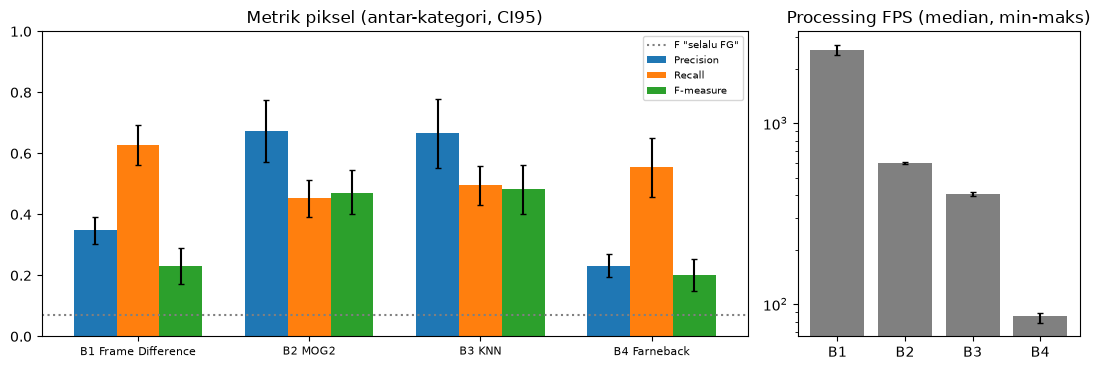

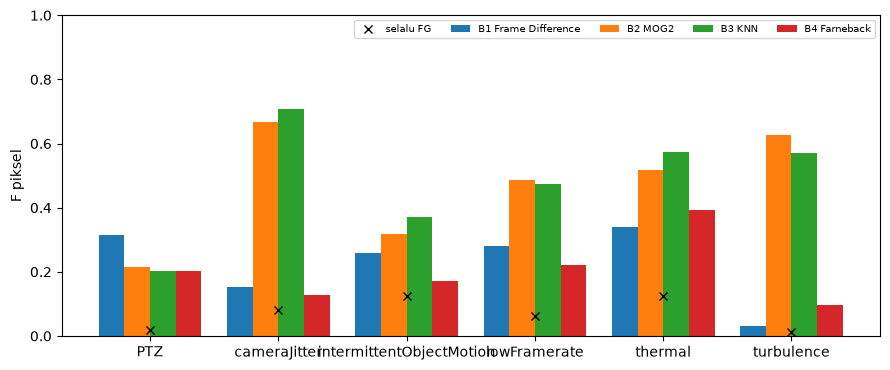

In [14]:
EX_T = list(EXP_TUN)
tl = {b + 't': LABELS[b] + ' (tuned)' for b in ALGOS}


def main_table(d, exps, labels, fps_col):
    rows = []
    for e in exps:
        row = {'Algoritma': labels[e]}
        for col, nm in (('px_precision', 'P'), ('px_recall', 'R')):
            row[nm] = fmt(cat_ci(d, e, col)[0])
        row['F [CI95]'] = fmt(*cat_ci(d, e, 'px_f'))
        row['PWC'] = fmt(cat_ci(d, e, 'px_pwc')[0], d=2)
        row['MCC frame'] = fmt(*cat_ci(d, e, 'mcc'))
        row['F1 box@0.5'] = fmt(cat_ci(d, e, 'box_f1')[0])
        row['IoU (TP)'] = fmt(cat_ci(d, e, 'iou_tp')[0])
        row['FPS (median)'] = f'{bench.loc[e, "fps_median"]:.0f}' if e in bench.index else '-'
        rows.append(row)
    return pd.DataFrame(rows)


tab = main_table(test, EX_T, tl, 'fps_median')
t_row = {'Algoritma': 'Selalu foreground (trivial)', 'P': fmt(cat_ci(triv, 'ALL-FG', 'px_precision')[0]),
         'R': fmt(cat_ci(triv, 'ALL-FG', 'px_recall')[0]), 'F [CI95]': fmt(*cat_ci(triv, 'ALL-FG', 'px_f')),
         'PWC': fmt(cat_ci(triv, 'ALL-FG', 'px_pwc')[0], d=2), 'MCC frame': '0', 'F1 box@0.5': '-',
         'IoU (TP)': '-', 'FPS (median)': '-'}
tab = pd.concat([tab, pd.DataFrame([t_row])], ignore_index=True)
save_table(tab, 'table_main', f'Hasil utama pada {len(test_seqs)} sekuens uji (rerata antar-kategori; metrik piksel CDnet; '
           'CI95 bootstrap bertingkat)')

# default vs tuned (split test) dan default pada seluruh sekuens
dv = []
for b in ALGOS:
    a = ALGOS[b]
    p = TUNE_GRID[a][0]
    dv.append({'Algoritma': LABELS[b], 'Parameter': p, 'Default': f'{ALGO_PARAMS[a][p]:g}', 'Tuned': f'{tuned[a][p]:g}',
               'F piksel default (test)': fmt(cat_ci(test, b, 'px_f')[0]),
               'F piksel tuned (test)': fmt(cat_ci(test, b + 't', 'px_f')[0]),
               'F piksel default (semua seq)': fmt(cat_ci(df, b, 'px_f')[0])})
save_table(pd.DataFrame(dv), 'table_default_vs_tuned', 'Konfigurasi default vs tuned (F piksel, rerata antar-kategori)')

# per kategori
rows = []
for cat in sorted(test.condition.unique()):
    sub = test[test.condition == cat]
    row = {'Kategori': cat, 'n': sub.seq.nunique()}
    for e in EX_T:
        row[LABELS[e[:-1]]] = fmt(sub[sub.exp == e].px_f.mean())
    row['Selalu FG'] = fmt(triv[triv.condition == cat].px_f.mean())
    rows.append(row)
save_table(pd.DataFrame(rows), 'table_by_category', 'F piksel per kategori CDnet (algoritma tuned, sekuens uji)')

# gambar utama
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [3, 1.2]})
w = 0.25
for i, (col, nm) in enumerate((('px_precision', 'Precision'), ('px_recall', 'Recall'), ('px_f', 'F-measure'))):
    ms = [cat_ci(test, e, col) for e in EX_T]
    a1.bar(np.arange(4) + (i - 1) * w, [m[0] for m in ms], w, label=nm,
           yerr=[[m[0] - m[1] for m in ms], [m[2] - m[0] for m in ms]], capsize=2)
a1.set_xticks(range(4)), a1.set_xticklabels([LABELS[e[:-1]] for e in EX_T], fontsize=8)
a1.axhline(cat_ci(triv, 'ALL-FG', 'px_f')[0], color='gray', ls=':', label='F "selalu FG"')
a1.set_ylim(0, 1), a1.legend(fontsize=7), a1.set_title('Metrik piksel (antar-kategori, CI95)')
a2.bar(range(4), bench.loc[EX_T, 'fps_median'],
       yerr=[bench.loc[EX_T, 'fps_median'] - bench.loc[EX_T, 'fps_min'],
             bench.loc[EX_T, 'fps_max'] - bench.loc[EX_T, 'fps_median']], capsize=2, color='gray')
a2.set_yscale('log'), a2.set_xticks(range(4)), a2.set_xticklabels([e[:-1] for e in EX_T])
a2.set_title('Processing FPS (median, min-maks)')
plt.tight_layout()
savefig(fig, 'fig_main')

fig, ax = plt.subplots(figsize=(9, 3.8))
cats = sorted(test.condition.unique())
for i, e in enumerate(EX_T):
    ax.bar(np.arange(len(cats)) + (i - 1.5) * 0.2, [test[(test.exp == e) & (test.condition == c)].px_f.mean() for c in cats],
           0.2, label=LABELS[e[:-1]])
ax.plot(range(len(cats)), [triv[triv.condition == c].px_f.mean() for c in cats], 'kx', label='selalu FG')
ax.set_xticks(range(len(cats))), ax.set_xticklabels(cats), ax.set_ylim(0, 1), ax.set_ylabel('F piksel')
ax.legend(fontsize=7, ncol=5)
plt.tight_layout()
savefig(fig, 'fig_by_category')


In [15]:
prim = paired_stats(test, 'px_f', [('B1t', 'B2t'), ('B1t', 'B3t'), ('B1t', 'B4t')])
sec_pairs = list(itertools.combinations(EX_T, 2))
sec_px = paired_stats(test, 'px_f', sec_pairs)
sec_mcc = paired_stats(test, 'mcc', sec_pairs)
sec_box = paired_stats(test, 'box_f1', sec_pairs)
nm = lambda st: {'Perbandingan': [f'{b} - {a}' for a, b in zip(st.a, st.b)]}
save_table(stats_table(prim, nm), 'stats_primary',
           'Perbandingan algoritma sekunder dua sisi (F piksel; sign-flip eksak kategori, Holm m=2). Uji terarah H1-H2 lihat tabel hipotesis.')
sec = pd.concat([stats_table(sec_px, nm).assign(Metrik='F piksel'), stats_table(sec_mcc, nm).assign(Metrik='MCC frame'),
                 stats_table(sec_box, nm).assign(Metrik='F1 box@0.5')])
save_table(sec[['Metrik'] + [c for c in sec.columns if c != 'Metrik']], 'stats_secondary',
           'Uji sekunder: 6 pasangan algoritma (sign-flip kategori; Holm per metrik)')
fr = test.pivot(index='seq', columns='exp', values='px_f')[EX_T].dropna()
if len(fr) >= 5:
    chi, pf = stats.friedmanchisquare(*[fr[c] for c in EX_T])
    msg = f'Friedman sekunder EKSPLORATORI per-sekuens (F piksel): chi2={chi:.3f}, p={fmt_p(pf)}, n={len(fr)}; tidak digunakan sebagai uji utama'
    print(msg), REPORT.append(msg + '\n')



== Perbandingan algoritma sekunder dua sisi (F piksel; sign-flip eksak kategori, Holm m=2). Uji terarah H1-H2 lihat tabel hipotesis. ==
Perbandingan  n sekuens  n kategori             efek [CI95] menang p kategori p Holm p Wilcoxon seq eksploratori
   B2t - B1t         27           6    0.241 [0.196, 0.285]  24/27      0.094  0.188                      <0.001
   B3t - B1t         27           6    0.253 [0.200, 0.303]  25/27      0.062  0.188                      <0.001
   B4t - B1t         27           6 -0.027 [-0.052, -0.005]   9/27      0.406  0.406                       0.077

== Uji sekunder: 6 pasangan algoritma (sign-flip kategori; Holm per metrik) ==
    Metrik Perbandingan  n sekuens  n kategori             efek [CI95] menang p kategori p Holm p Wilcoxon seq eksploratori
  F piksel    B2t - B1t         27           6    0.241 [0.196, 0.284]  24/27      0.094  0.312                      <0.001
  F piksel    B3t - B1t         27           6    0.253 [0.199, 0.303]  25/27      


== Ablasi faktorial frame_diff (b=blur, m=morfologi; tuned; sekuens uji) ==
        Sel     P     R             F [CI95]
b0-fixed-m0 0.177 0.580 0.162 [0.122, 0.206]
b0-fixed-m1 0.314 0.655 0.223 [0.168, 0.280]
 b0-otsu-m0 0.358 0.298 0.168 [0.119, 0.216]
 b0-otsu-m1 0.430 0.305 0.210 [0.163, 0.256]
b1-fixed-m0 0.323 0.525 0.200 [0.148, 0.251]
b1-fixed-m1 0.350 0.627 0.230 [0.173, 0.290]
 b1-otsu-m0 0.404 0.288 0.185 [0.136, 0.233]
 b1-otsu-m1 0.427 0.347 0.218 [0.165, 0.270]

== Efek faktorial frame_diff (kontras on-off, sign-flip kategori, Holm per metrik) ==
      Metrik                Efek  n sekuens  n kategori             efek [CI95] menang p kategori p Holm p Wilcoxon seq eksploratori
        px_f                blur         27           6    0.017 [0.002, 0.035]  20/27      0.250  1.000                       0.058
        px_f                otsu         27           6  -0.009 [-0.033, 0.015]  14/27      0.844  1.000                       0.485
        px_f               morph

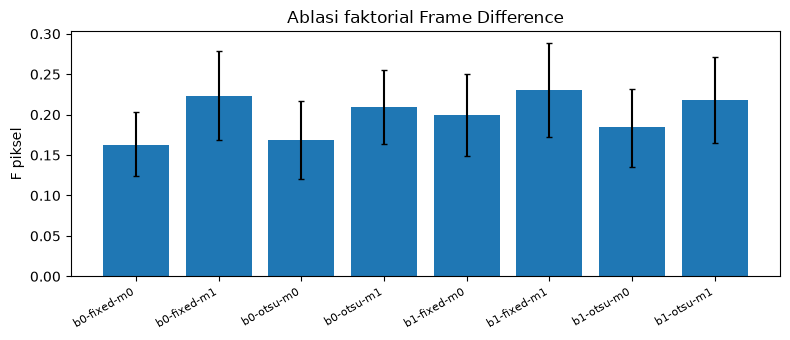

In [16]:
hyp_rows = []
abl_effects = {}
if CFG['run_ablation']:
    for algo in ABLATION_ALGOS:
        otsu_ok = algo in ('frame_diff', 'farneback')
        cells = {}
        for b, t, m in itertools.product((0, 1), (('fixed', 'otsu') if otsu_ok else ('fixed',)), (0, 1)):
            cells[f'{algo}:b{b}-{t}-m{m}'] = (b, int(t == 'otsu'), m) if otsu_ok else (b, m)
        factors = ['blur', 'otsu', 'morph'] if otsu_ok else ['blur', 'morph']
        rows = []
        for cid, lv in cells.items():
            row = {'Sel': cid.split(':')[1]}
            for col, nm_ in (('px_precision', 'P'), ('px_recall', 'R'), ('px_f', 'F [CI95]')):
                row[nm_] = fmt(*cat_ci(test, cid, col)) if col == 'px_f' else fmt(cat_ci(test, cid, col)[0])
            rows.append(row)
        save_table(pd.DataFrame(rows), f'table_ablation_cells_{algo}',
                   f'Ablasi faktorial {algo} (b=blur, m=morfologi; tuned; sekuens uji)')
        eff = {}
        for met in ('px_f', 'px_precision', 'px_recall', 'px_fpr'):
            eff[met] = factorial_effects(test, cells, factors, met)
        abl_effects[algo] = eff
        e_tab = pd.concat([stats_table(eff[m_], lambda s: {'Efek': s['efek_nama']}).assign(Metrik=m_) for m_ in eff])
        save_table(e_tab[['Metrik'] + [c for c in e_tab.columns if c != 'Metrik']], f'stats_ablation_{algo}',
                   f'Efek faktorial {algo} (kontras on-off, sign-flip kategori, Holm per metrik)')
    # sensitivitas lantai Otsu
    fl = pd.DataFrame([{'Lantai Otsu': f, 'P': fmt(cat_ci(test, f'frame_diff:otsu_floor={f}', 'px_precision')[0]),
                        'R': fmt(cat_ci(test, f'frame_diff:otsu_floor={f}', 'px_recall')[0]),
                        'F [CI95]': fmt(*cat_ci(test, f'frame_diff:otsu_floor={f}', 'px_f'))} for f in OTSU_FLOORS])
    save_table(fl, 'table_otsu_floor', 'Sensitivitas lantai Otsu (frame difference, blur + Otsu + morfologi)')

    fig, ax = plt.subplots(figsize=(8, 3.5))
    cid = [k for k in exps_all if k.startswith('frame_diff:b') and '-' in k]
    ms = [cat_ci(test, k, 'px_f') for k in cid]
    ax.bar(range(len(cid)), [m[0] for m in ms], yerr=[[m[0] - m[1] for m in ms], [m[2] - m[0] for m in ms]], capsize=2)
    ax.set_xticks(range(len(cid))), ax.set_xticklabels([k.split(':')[1] for k in cid], rotation=30, ha='right', fontsize=8)
    ax.set_ylabel('F piksel'), ax.set_title('Ablasi faktorial Frame Difference')
    plt.tight_layout()
    savefig(fig, 'fig_ablation')


In [17]:
# Hipotesis pra-registrasi untuk pengujian lintas-kategori BARU (lihat PROTOCOL.md).
# Pada development, ini adalah analisis *eksploratori* karena hasil v2 sudah pernah ditinjau.
hyp = []
wt = test.pivot(index='seq', columns='exp', values='px_f')
ct = seq_cat(test)
hyp.extend([
    ('H1: MOG2 > Frame Difference (F piksel)', 'F piksel', +1, wt['B2t'] - wt['B1t'], ct),
    ('H2: KNN > Frame Difference (F piksel)', 'F piksel', +1, wt['B3t'] - wt['B1t'], ct),
])

def eff_series(algo, met, factor):
    cells = {f'{algo}:b{b}-{t}-m{m}': (b, int(t == 'otsu'), m)
             for b, t, m in itertools.product((0, 1), ('fixed', 'otsu'), (0, 1))}
    wide = test[test.exp.isin(list(cells))].pivot(index='seq', columns='exp', values=met).dropna()
    idx = ['blur', 'otsu', 'morph'].index(factor)
    return sum(wide[c] * (2 * cells[c][idx] - 1) for c in cells) / 4

if CFG['run_ablation'] and 'frame_diff' in ABLATION_ALGOS:
    hyp.extend([
        ('H3: Blur menurunkan FPR Frame Difference', 'FPR piksel', -1,
         eff_series('frame_diff', 'px_fpr', 'blur'), ct),
        ('H4: Morphology meningkatkan F1 Frame Difference', 'F piksel', +1,
         eff_series('frame_diff', 'px_f', 'morph'), ct),
    ])
ht = pd.DataFrame([{'h': h, 'metrik': metric, 'arah': sign, **contrast_row(x, cat)}
                   for h, metric, sign, x, cat in hyp])
# Dua keluarga berbeda, bukan memilih hanya hipotesis yang signifikan:
# algoritma H1-H2; preprocessing H3-H4.
ht['family'] = ['algoritma' if h.startswith(('H1:', 'H2:')) else 'preprocessing' for h in ht.h]
# Preregistered directional alternative. With only six categories, two-sided exact
# sign-flip + Holm for 2 tests has minimum corrected p=0.0625 (no power to reject).
# One-sided is justified only because sign was frozen in PROTOCOL.md BEFORE new data.
ht['p_two_sided'] = ht['p']
for idx, (_, _, sign, contrast, cats) in enumerate(hyp):
    contrast = contrast.dropna()
    per_category = np.asarray([contrast[cats.loc[contrast.index] == k].mean()
                               for k in sorted(cats.loc[contrast.index].unique())])
    ht.loc[idx, 'p'] = category_signflip_p(per_category,
                                           alternative='greater' if sign > 0 else 'less')
ht['p_holm'] = np.nan
for fam, indices in ht.groupby('family').groups.items():
    ht.loc[list(indices), 'p_holm'] = holm_adjust(ht.loc[list(indices), 'p'].to_numpy())


def verdict(r):
    if pd.isna(r.p_holm):
        return 'tidak dapat diuji'
    if r.p_holm < 0.05:
        return 'arah didukung' if np.sign(r.efek) == r.arah else 'arah berlawanan'
    return 'tidak signifikan'

hyp_tab = pd.DataFrame({
    'Hipotesis': ht.h, 'Keluarga': ht.family, 'Metrik': ht.metrik,
    'n kategori': ht.n_categories,
    'Efek [CI95]': [fmt(r.efek, r.ci_lo, r.ci_hi) for r in ht.itertuples()],
    'p satu sisi kategori': [fmt_p(p) for p in ht.p],
    'p dua sisi (deskriptif)': [fmt_p(p) for p in ht.p_two_sided],
    'p Holm': [fmt_p(p) for p in ht.p_holm],
    'Keputusan statistik': [verdict(r) for r in ht.itertuples()],
})
save_table(hyp_tab, 'table_hypotheses',
           f'Hipotesis {CFG["mode"]} (uji satu sisi terarah eksak per kategori; Holm per keluarga)')



== Hipotesis confirmatory (uji satu sisi terarah eksak per kategori; Holm per keluarga) ==
                                      Hipotesis      Keluarga     Metrik  n kategori             Efek [CI95] p satu sisi kategori p dua sisi (deskriptif) p Holm Keputusan statistik
         H1: MOG2 > Frame Difference (F piksel)     algoritma   F piksel           6    0.241 [0.196, 0.285]                0.047                   0.094  0.062    tidak signifikan
          H2: KNN > Frame Difference (F piksel)     algoritma   F piksel           6    0.253 [0.201, 0.304]                0.031                   0.062  0.062    tidak signifikan
       H3: Blur menurunkan FPR Frame Difference preprocessing FPR piksel           6 -0.028 [-0.036, -0.020]                0.016                   0.031  0.031       arah didukung
H4: Morphology meningkatkan F1 Frame Difference preprocessing   F piksel           6    0.041 [0.029, 0.057]                0.016                   0.031  0.031       arah didukung


In [18]:
if CFG['run_gt_sensitivity']:
    rows, tau_rows = [], []
    ref = None
    for v in VARIANTS:
        pre = '' if v == 'primer' else f'{v}__'
        cm = catmean(test[test.exp.isin(EX_T)], [pre + 'box_f1']).loc[EX_T, pre + 'box_f1']
        cmi = catmean(test[test.exp.isin(EX_T)], [pre + 'iou']).loc[EX_T, pre + 'iou']
        if ref is None:
            ref = cm
        tau = stats.kendalltau(ref.values, cm.values)[0]
        order = ' > '.join(e[:-1] for e in cm.sort_values(ascending=False).index)
        rows.append({'Varian GT': v, **{e[:-1] + ' F1 box': fmt(cm[e]) for e in EX_T}, 'Urutan': order,
                     'tau vs primer': fmt(tau, d=2)})
    save_table(pd.DataFrame(rows), 'table_gt_sensitivity',
               'Sensitivitas terhadap konstruksi box GT (tuned, sekuens uji): peringkat stabil bila urutan & tau tetap')



== Sensitivitas terhadap konstruksi box GT (tuned, sekuens uji): peringkat stabil bila urutan & tau tetap ==
  Varian GT B1 F1 box B2 F1 box B3 F1 box B4 F1 box            Urutan tau vs primer
     primer     0.097     0.272     0.281     0.061 B3 > B2 > B1 > B4          1.00
tanpa_close     0.096     0.269     0.280     0.061 B3 > B2 > B1 > B4          1.00
     close9     0.100     0.263     0.272     0.063 B3 > B2 > B1 > B4          1.00
 area_kecil     0.096     0.263     0.275     0.061 B3 > B2 > B1 > B4          1.00
 area_besar     0.098     0.269     0.280     0.063 B3 > B2 > B1 > B4          1.00


In [19]:
fps_tab = bench.round(1).reset_index().rename(columns={'exp': 'Eksperimen'})
fps_tab['Eksperimen'] = [LABELS.get(e.rstrip('t'), e) + (' (tuned)' if e.endswith('t') else ' (default)') for e in fps_tab['Eksperimen']]
save_table(fps_tab, 'table_fps', f"Processing FPS per algoritma secara terisolasi: serial, {CFG['cv_threads']} thread OpenCV, {CFG['bench_frames']} frame pertama "
           f"dari 1 sekuens/kategori, median dari {CFG['bench_repeats']} pengulangan")



== Processing FPS per algoritma secara terisolasi: serial, 1 thread OpenCV, 300 frame pertama dari 1 sekuens/kategori, median dari 5 pengulangan ==
                   Eksperimen  fps_median  fps_min  fps_max
B1 Frame Difference (default)      1976.4   1605.1   3545.0
            B2 MOG2 (default)       556.9    380.9    566.5
             B3 KNN (default)       362.6    350.9    363.6
       B4 Farneback (default)        85.3     84.6     85.8
  B1 Frame Difference (tuned)      2545.9   2380.5   2691.0
              B2 MOG2 (tuned)       598.2    591.4    612.7
               B3 KNN (tuned)       403.2    396.9    415.0
         B4 Farneback (tuned)        85.8     79.1     88.7


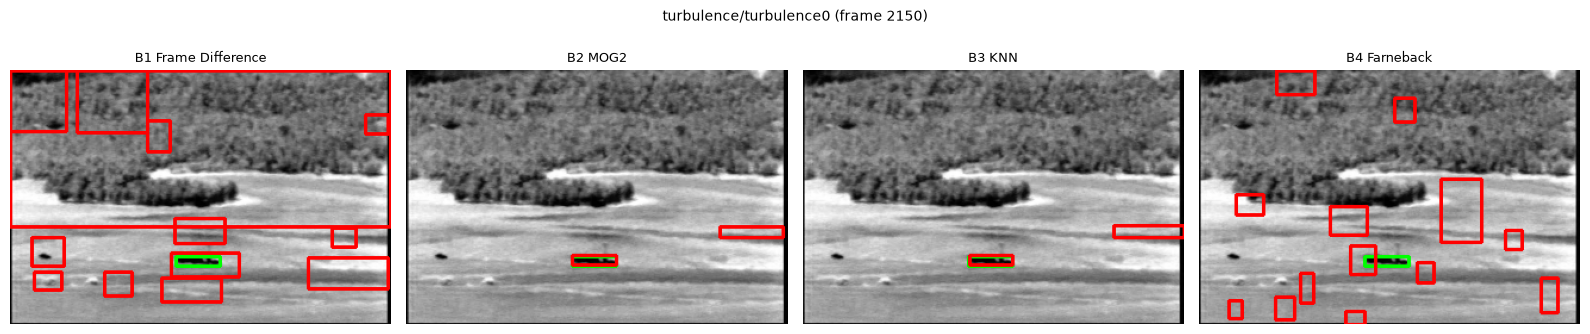

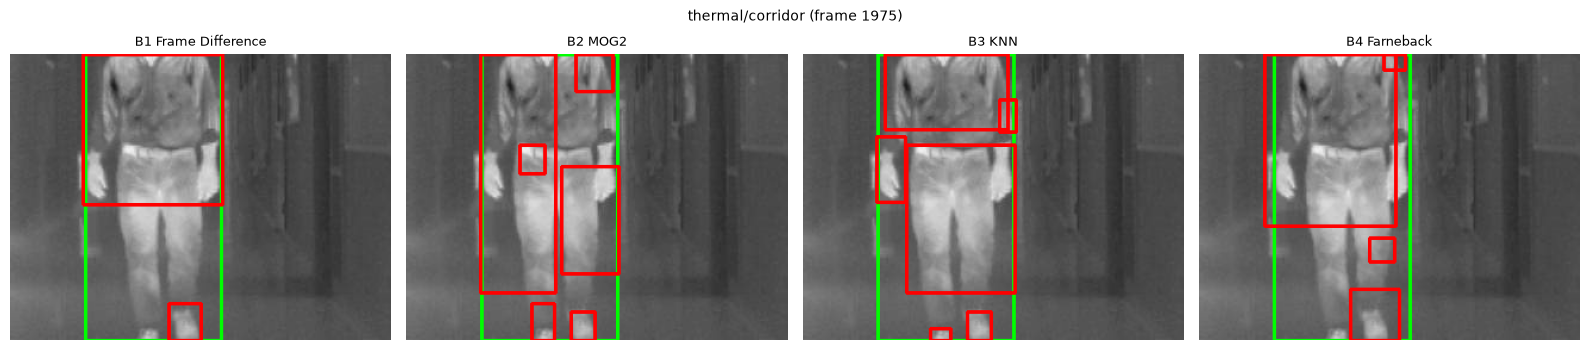

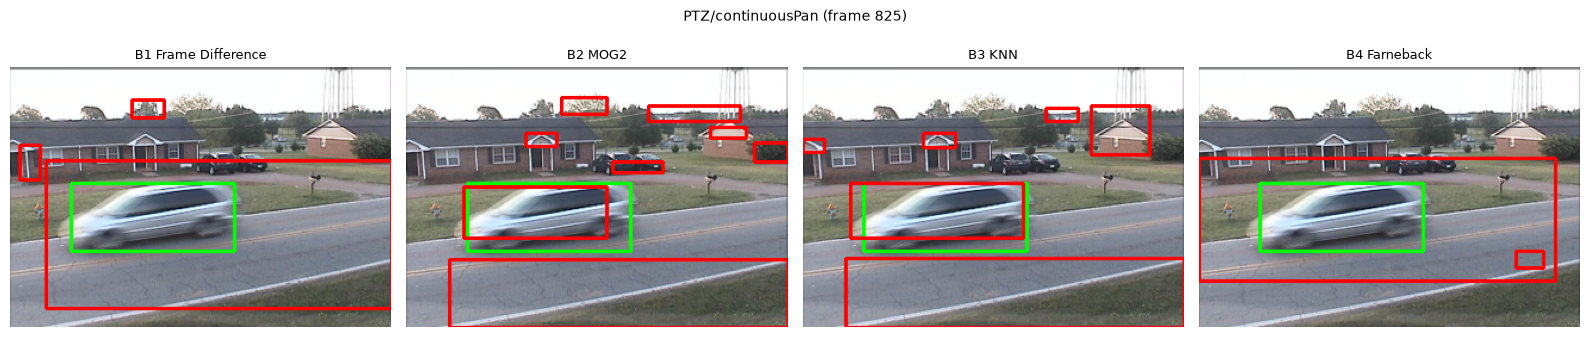

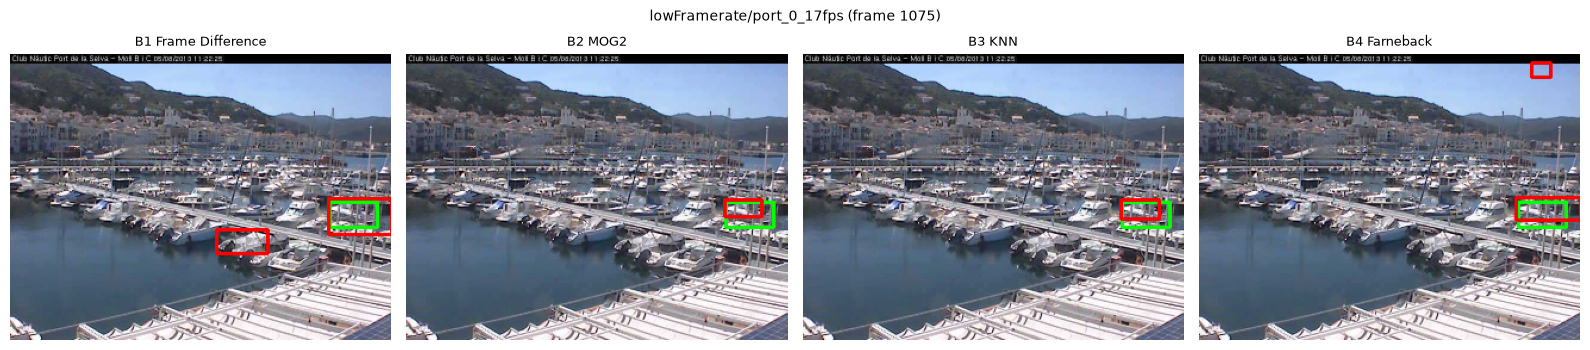

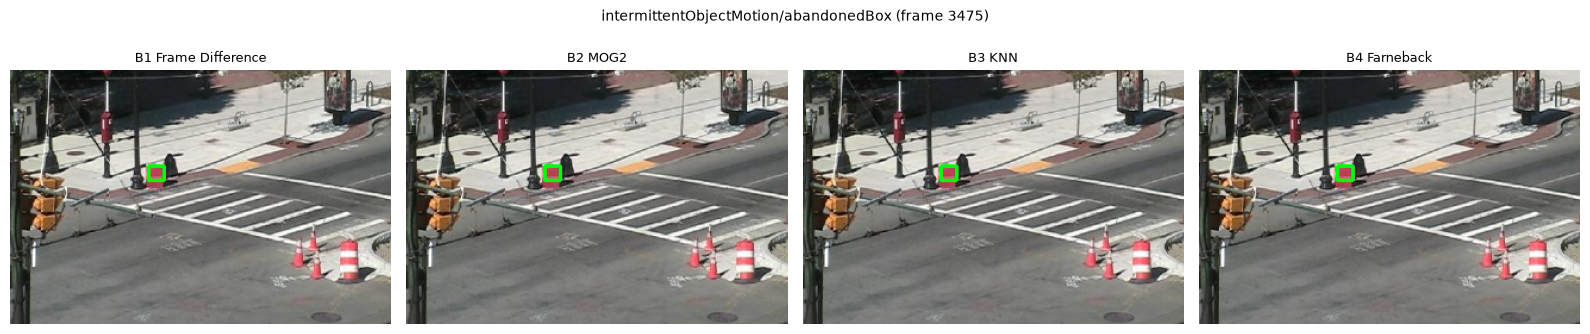

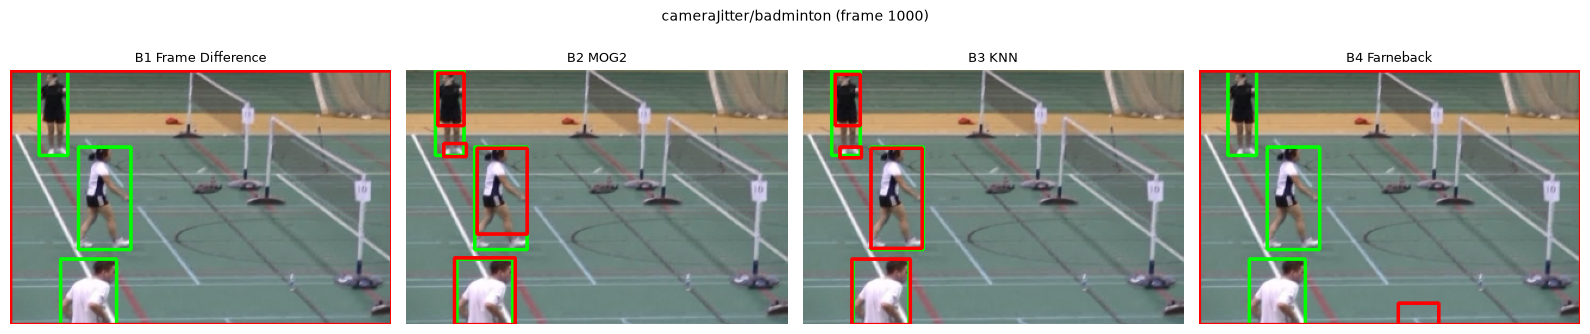

In [20]:
def pick_example_frame(seq):
    cands = []
    for n in sorted(seq['gts']):
        if seq['roi_start'] <= n <= seq['last'] and (n - seq['roi_start']) % 25 == 0:
            g = cv2.imread(str(seq['gts'][n]), cv2.IMREAD_GRAYSCALE)
            if g is not None and np.count_nonzero(g == MOTION) > 0.002 * g.size:
                cands.append(n)
    return cands[len(cands) // 2] if cands else (seq['roi_start'] + seq['last']) // 2


def save_examples(seq, experiments, name):
    W, H = seq['size']
    target = pick_example_frame(seq)
    g = cv2.imread(str(seq['gts'].get(target, '')), cv2.IMREAD_GRAYSCALE) if target in seq['gts'] else None
    gt_b = EMPTY
    if g is not None:
        g = cv2.resize(g, (W, H), interpolation=cv2.INTER_NEAREST)
        gt_b = gt_boxes_from_labels(g, GT_VARIANTS['primer'], W * H, {})
    fig, axes = plt.subplots(1, len(experiments), figsize=(4 * len(experiments), 3.6))
    for ax, (e, cfg) in zip(np.atleast_1d(axes), experiments.items()):
        det, frame, boxes = MotionDetector(frame_area=W * H, **cfg), None, EMPTY
        for n, path in seq['inputs'].items():
            if n > target:
                break
            f = cv2.imread(str(path))
            if f is None:
                continue
            frame = cv2.resize(f, seq['size'], interpolation=cv2.INTER_AREA)
            boxes = det.process(frame, seq['roi'])
        if frame is None:
            continue
        for b in gt_b:
            cv2.rectangle(frame, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (0, 255, 0), 2)
        for b in boxes:
            cv2.rectangle(frame, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (0, 0, 255), 2)
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(LABELS[e[:-1]], fontsize=9)
        ax.axis('off')
    fig.suptitle(f"{seq['id']} (frame {target})", fontsize=10)
    plt.tight_layout()
    savefig(fig, name)


if CFG['qualitative']:
    pool = test_seqs or seqs
    for s in {s['category']: s for s in reversed(pool)}.values():  # satu sekuens per kategori
        save_examples(s, EXP_TUN, f"fig_examples_{s['id'].replace('/', '_')}")


In [21]:
def cpu_model():
    try:
        with open('/proc/cpuinfo') as fh:
            for line in fh:
                if line.startswith('model name'):
                    return line.split(':', 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or 'unknown'


run_info = {'cpu': cpu_model(), 'platform': platform.platform(), 'python': sys.version.split()[0],
            'opencv': cv2.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
            'cfg': CFG, 'algo_params': ALGO_PARAMS, 'tuned_params': tuned, 'tune_grid': TUNE_GRID,
            'std_pipeline': STD, 'gt_variants': GT_VARIANTS,
            'split': {s['id']: s['split'] for s in seqs},
            'protocol_audit': PROTOCOL_AUDIT,
            'phase_disclosure': 'CONFIRMATORY, previously unseen categories' if CFG['mode'] == 'confirmatory'
                                else 'EXPLORATORY, version 2 test data already examined',
            'historical_manifest_sha256': hashlib.sha256(Path(CFG['historical_manifest']).read_bytes()).hexdigest(),
            'frozen_params_sha256': (hashlib.sha256(Path(CFG['tuned_params_file']).read_bytes()).hexdigest()
                                      if CFG['tuned_params_file'] else None),
            'dataset_identity': {s['id']: {'n_scored': s['n_scored'], 'roi': [s['roi_start'], s['roi_end']],
                                          'resolution': s['size']} for s in seqs}}
(OUT / 'run_info.json').write_text(json.dumps(run_info, indent=2, default=str))

setup = [
    f'# Laporan Eksperimen B v3 — {CFG["mode"].upper()} (CDnet 2014)\n',
    f'**STATUS:** {run_info["phase_disclosure"]}. Jangan menyebut hasil development sebagai confirmatory.  ',
    f"**Data:** {len(seqs)} sekuens, kategori {', '.join(sorted({s['category'] for s in seqs}))}; "
    f"{len(tune_seqs)} sekuens tune, {len(test_seqs)} sekuens test (seed {CFG['seed']}, lihat `splits.csv`).  ",
    f"**Resolusi kerja:** {str(CFG['resize_width']) + ' px (lebar)' if CFG['resize_width'] else 'asli'}. **Pipeline B1-B4:** blur {STD['blur_ksize']}x{STD['blur_ksize']}, "
    f"ambang tetap, morfologi open(3)+close(7), kontur >= {CFG['min_area_ratio']:.2%} luas frame.  ",
    f"**Lingkungan:** {run_info['cpu']}, OpenCV {cv2.__version__}, Python {run_info['python']}.  ",
    f"**Parameter terpilih (tune):** `{json.dumps(tuned)}`.\n",
    '**Definisi metrik.** Piksel (utama): label GT 255 = positif; 0 dan 50 (hard shadow) = negatif; 85 (luar ROI) dan 170 (unknown) diabaikan; prediksi di luar ROI dinolkan; '
    'metrik dihitung per sekuens lalu dirata-rata per kategori dan antar-kategori. Frame: positif = ada >= 1 box; MCC. '
    f"Box GT diturunkan dari mask label 255 (closing {CFG['gt_close_kernel']}x{CFG['gt_close_kernel']}, kontur >= {CFG['min_area_ratio']:.2%} luas); "
    f"TP box = pencocokan satu-ke-satu dengan IoU >= {CFG['iou_thr']}. 'IoU (TP)' = rerata IoU pasangan TP.\n",
]
limits = [
    '## Keterbatasan (cantumkan di paper)\n',
    '- Box GT diturunkan dari mask piksel, bukan anotasi manusia; lihat sensitivitas GT.',
    '- Metrik piksel dihitung pada resolusi kerja (bukan resolusi asli) bila `resize_width` diisi; tidak setara persis dengan papan peringkat resmi CDnet.',
    '- Rerata aritmetika per sekuens -> kategori -> keseluruhan mengikuti konvensi CDnet; rerata F per sekuens tidak sama dengan F dari rerata Precision/Recall.',
    '- Hanya lima kategori (kamera diam); PTZ, cameraJitter, turbulence, dll. tidak dinilai.',
    '- Satu parameter sensitivitas per algoritma yang dituning; parameter lain default.',
    '- Uji sign-flip menggunakan rerata per kategori sebagai unit inferensial; CI bootstrap bersyarat kategori tetap.',
    '- Data development/test v2 telah ditinjau dan bersifat eksploratori, bukan holdout buta yang baru.',
    '- Enam kategori confirmatory merupakan distribusi kondisi berbeda (domain shift), bukan sampel IID dari 5 kategori awal.',
    '- Komparasi threshold 320px tidak langsung setara dengan benchmark leaderboard resolusi asli.',
    '- FPS spesifik perangkat/versi OpenCV; diukur serial pada subset frame.',
]
(OUT / 'report.md').write_text('\n'.join(setup + REPORT + limits) + '\n', encoding='utf-8')
print(f'\nSelesai. Semua keluaran ada di: {OUT.resolve()}')



Selesai. Semua keluaran ada di: C:\Users\Administrator\PycharmProjects\experiment_b_cdnet2014\CDnet2014_Paper_Research_V3\cdnet_paper_v3\working\results-v3-confirmatory
